In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time
import os
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

# Load dataset
data_path = "../data/clustering_dataset.csv"
df = pd.read_csv(data_path)

# Scale features
scaler = StandardScaler()
X = scaler.fit_transform(df.values)

print(f"Dataset loaded: {X.shape[0]} points.")

Dataset loaded: 12000 points.


In [2]:
class HDBSCAN:
    """HDBSCAN implementation from scratch."""
    def __init__(self, min_cluster_size=15, min_samples=5):
        self.min_cluster_size = min_cluster_size
        self.min_samples = min_samples
        self.labels = None
        self.n_clusters = 0

    def _compute_core_distances(self, X):
        n = X.shape[0]
        core_dists = np.zeros(n)
        chunk_size = 500
        for start in range(0, n, chunk_size):
            end = min(start + chunk_size, n)
            # Vectorized Euclidean distance for chunk
            dists = np.sqrt(((X[start:end, np.newaxis, :] - X[np.newaxis, :, :]) ** 2).sum(axis=2))
            core_dists[start:end] = np.sort(dists, axis=1)[:, self.min_samples]
        return core_dists

    def _prim_mst(self, X, core_dists):
        """MST via Prim's on the mutual reachability graph."""
        n = X.shape[0]
        in_tree = np.zeros(n, dtype=bool)
        min_cost = np.full(n, np.inf)
        min_from = np.full(n, -1, dtype=int)
        edges = []

        current = 0
        in_tree[current] = True
        
        # Initial distance update
        dists = np.sqrt(np.sum((X - X[current]) ** 2, axis=1))
        mreach = np.maximum(np.maximum(core_dists[current], core_dists), dists)
        mask = ~in_tree & (mreach < min_cost)
        min_cost[mask] = mreach[mask]
        min_from[mask] = current

        for step in range(n - 1):
            candidates = np.where(~in_tree)[0]
            best_idx = candidates[np.argmin(min_cost[candidates])]

            edges.append((min_cost[best_idx], min_from[best_idx], best_idx))
            in_tree[best_idx] = True

            dists = np.sqrt(np.sum((X - X[best_idx]) ** 2, axis=1))
            mreach = np.maximum(np.maximum(core_dists[best_idx], core_dists), dists)
            mask = ~in_tree & (mreach < min_cost)
            min_cost[mask] = mreach[mask]
            min_from[mask] = best_idx
            
        return edges

    def _extract_clusters(self, edges, n):
        """Builds dendrogram and extracts clusters using stability."""
        edges_sorted = sorted(edges, key=lambda e: e[0])
        mcs = self.min_cluster_size

        # --- Part A: Single Linkage Hierarchy (Union-Find) ---
        tree = []
        uf_parent = {i: i for i in range(n)}
        def find(x):
            while uf_parent[x] != x:
                uf_parent[x] = uf_parent[uf_parent[x]]
                x = uf_parent[x]
            return x

        cluster_size = {i: 1 for i in range(n)}
        node_id_map = {i: i for i in range(n)}
        current_cluster = n

        for w, a, b in edges_sorted:
            ra, rb = find(a), find(b)
            if ra == rb: continue
            id_a, id_b = node_id_map[ra], node_id_map[rb]
            new_sz = cluster_size[id_a] + cluster_size[id_b]
            tree.append({'id': current_cluster, 'left': id_a, 'right': id_b, 'dist': w, 'size': new_sz})
            cluster_size[current_cluster] = new_sz
            uf_parent[rb] = ra
            node_id_map[ra] = current_cluster
            current_cluster += 1

        # --- Part B: Condensing Tree and Stability ---
        children_dict = {nd['id']: (nd['left'], nd['right'], nd['dist']) for nd in tree}
        size_dict = cluster_size.copy()
        for i in range(n): size_dict[i] = 1

        def get_leaves(n_id):
            stack, leaves = [n_id], []
            while stack:
                curr = stack.pop()
                if curr < n: leaves.append(curr)
                else:
                    l, r, _ = children_dict[curr]
                    stack.extend([l, r])
            return leaves

        root_id = 2 * n - 2
        cluster_info = {0: {'birth': 0.0, 'points': [], 'children': []}}
        next_cl_id = 1
        node_to_cl = {root_id: 0}

        stack = [root_id]
        while stack:
            node = stack.pop()
            if node < n: continue
            l, r, d = children_dict[node]
            lam = 1.0 / d if d > 0 else float("inf")
            cl_id = node_to_cl[node]
            
            if size_dict[l] >= mcs and size_dict[r] >= mcs:
                cl_l, cl_r = next_cl_id, next_cl_id + 1
                next_cl_id += 2
                cluster_info[cl_id]['children'].extend([cl_l, cl_r])
                cluster_info[cl_id]['death'] = lam
                cluster_info[cl_l] = {'birth': lam, 'points': [], 'children': []}
                cluster_info[cl_r] = {'birth': lam, 'points': [], 'children': []}
                node_to_cl[l], node_to_cl[r] = cl_l, cl_r
                stack.extend([l, r])
            elif size_dict[l] >= mcs:
                node_to_cl[l] = cl_id
                cluster_info[cl_id]['points'].extend([(p, lam) for p in get_leaves(r)])
                stack.append(l)
            elif size_dict[r] >= mcs:
                node_to_cl[r] = cl_id
                cluster_info[cl_id]['points'].extend([(p, lam) for p in get_leaves(l)])
                stack.append(r)
            else:
                cluster_info[cl_id]['death'] = lam
                cluster_info[cl_id]['points'].extend([(p, lam) for p in get_leaves(l)])
                cluster_info[cl_id]['points'].extend([(p, lam) for p in get_leaves(r)])

        # --- Part C: Selection ---
        def get_stab(c):
            s = sum((p[1] - cluster_info[c]['birth']) for p in cluster_info[c]['points'])
            if 'death' in cluster_info[c]:
                child_pts = 0
                c_stack = list(cluster_info[c]['children'])
                while c_stack:
                    curr = c_stack.pop()
                    child_pts += len(cluster_info[curr]['points'])
                    c_stack.extend(cluster_info[curr]['children'])
                s += child_pts * (cluster_info[c]['death'] - cluster_info[c]['birth'])
            return s

        stabs = {c: get_stab(c) for c in cluster_info}
        prop_stab = {}
        selected = {c: False for c in cluster_info}
        for c in sorted(cluster_info.keys(), reverse=True):
            child_sum = sum(prop_stab[child] for child in cluster_info[c]['children'])
            if c != 0 and stabs[c] >= child_sum:
                prop_stab[c], selected[c] = stabs[c], True
            else:
                prop_stab[c], selected[c] = child_sum, False

        # Final Assignment
        labels = np.full(n, -1, dtype=int)
        cid, final_stack = 0, [0]
        while final_stack:
            c = final_stack.pop()
            if selected[c]:
                pts, s_stack = [], [c]
                while s_stack:
                    curr = s_stack.pop()
                    pts.extend(p[0] for p in cluster_info[curr]['points'])
                    s_stack.extend(cluster_info[curr]['children'])
                labels[pts] = cid
                cid += 1
            else: final_stack.extend(cluster_info[c]['children'])
        
        self.labels, self.n_clusters = labels, cid

    def fit(self, X):
        core_dists = self._compute_core_distances(X)
        edges = self._prim_mst(X, core_dists)
        self._extract_clusters(edges, X.shape[0])
        return self

In [3]:
# Parameters
MIN_CLUSTER_SIZE = 25 
MIN_SAMPLES = 10

start_time = time.time()
model = HDBSCAN(min_cluster_size=MIN_CLUSTER_SIZE, min_samples=MIN_SAMPLES)
model.fit(X)
run_time = time.time() - start_time

labels = model.labels
n_clusters = model.n_clusters
n_noise = np.sum(labels == -1)

# Metric Calculation (Filtering Noise for fairness)
mask = (labels != -1)
if n_clusters > 1 and np.any(mask):
    sil = silhouette_score(X[mask], labels[mask])
    db = davies_bouldin_score(X[mask], labels[mask])
    ch = calinski_harabasz_score(X[mask], labels[mask])
else:
    sil = db = ch = np.nan

print(f"HDBSCAN Result: {n_clusters} clusters, {n_noise} noise points.")

# Save to results.csv
results_path = "../results.csv"
res_df = pd.DataFrame([{
    "model": "hdbscan", "n_clusters": n_clusters, "epsilon": "N/A", "min_pts": MIN_SAMPLES,
    "inertia": 0, "silhouette": sil, "davies_bouldin_score": db, 
    "calinski_harabasz_score": ch, "n_noise": n_noise, "run_time": run_time
}])
res_df.to_csv(results_path, mode='a', header=not os.path.exists(results_path), index=False)

HDBSCAN Result: 8 clusters, 75 noise points.


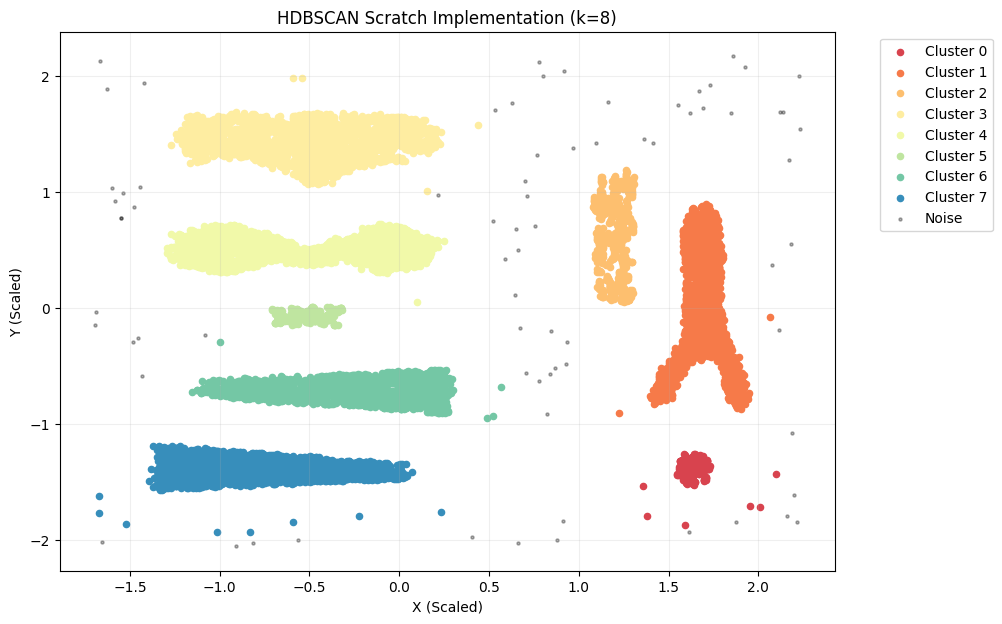

In [4]:
plt.figure(figsize=(10, 7))

# Create palette
unique_labels = set(labels)
palette = sns.color_palette('Spectral', n_clusters)

for label in unique_labels:
    idx = (labels == label)
    if label == -1:
        plt.scatter(X[idx, 0], X[idx, 1], c='black', s=5, label='Noise', alpha=0.3)
    else:
        plt.scatter(X[idx, 0], X[idx, 1], color=palette[label], s=20, label=f'Cluster {label}')

plt.title(f"HDBSCAN Scratch Implementation (k={n_clusters})")
plt.xlabel("X (Scaled)")
plt.ylabel("Y (Scaled)")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(alpha=0.2)
plt.show()